# Kaggle — House Prices : Advanced Regression Techniques

In [935]:
# Recharge automatiquement src/transformers.py quand il est modifié
%load_ext autoreload
%autoreload 2

# Rend le dossier src/ (un niveau au-dessus de notebooks/) importable
import sys
sys.path.append("..")
from src.transformers import GroupMedianImputer, ModeImputer

import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

train = pd.read_csv("../data/train.csv")
test = pd.read_csv("../data/test.csv")
test_ids = test["Id"]  # Id du test, nécessaires pour la soumission

train.shape, test.shape

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


((1460, 81), (1459, 80))

## 1. Préparation des données

In [936]:
train = train.reset_index(drop=True)

# Cible passée en log (la métrique Kaggle est un RMSE sur le log du prix)
y = np.log1p(train["SalePrice"])

# Features uniquement : on retire l'identifiant et la cible
X_train = train.drop(columns=["Id", "SalePrice"])
X_test  = test.drop(columns=["Id"])

# Concaténation train + test ; n_train sert à re-séparer plus tard
n_train = len(X_train)
all_X = pd.concat([X_train, X_test], axis=0, ignore_index=True)

In [937]:
all_X.shape  # attendu : (2919, 79)

(2919, 79)

## 2. Valeurs manquantes

In [938]:
# Colonnes qui contiennent au moins un NaN
cols_na = all_X.columns[all_X.isnull().any()]
df_null = all_X[cols_na]

# Nombre et pourcentage de NaN, triés par ordre décroissant
na = df_null.isnull().sum().sort_values(ascending=False)
na_pct = (na / len(all_X) * 100).round(1)
pd.DataFrame({"nb_NaN": na, "pct": na_pct})

,nb_NaN,pct
PoolQC,2909,99.7
MiscFeature,2814,96.4
Alley,2721,93.2
Fence,2348,80.4
MasVnrType,1766,60.5
FireplaceQu,1420,48.6
LotFrontage,486,16.6
GarageQual,159,5.4
GarageYrBlt,159,5.4
GarageCond,159,5.4


### 2.1 `PoolQC` — qualité de la piscine (99,7 % de NaN)

D'après `data_description.txt`, `NA` = pas de piscine. On vérifie que les NaN correspondent aux maisons avec `PoolArea == 0`.

In [939]:
# Seulement 10 piscines ont une qualité renseignée
all_X['PoolQC'].value_counts()

PoolQC
Ex    4
Gd    4
Fa    2
Name: count, dtype: int64

**Test de cohérence `PoolQC` × `PoolArea`**

In [940]:
# Maisons sans piscine
(all_X['PoolArea'] == 0).sum()

np.int64(2906)

In [941]:
# Pas de piscine ET pas de qualité -> cohérent
((all_X['PoolArea'] == 0) & (all_X['PoolQC'].isnull())).sum()

np.int64(2906)

In [942]:
# Piscine présente MAIS qualité manquante -> vraies valeurs manquantes
((all_X['PoolArea'] > 0) & (all_X['PoolQC'].isnull())).sum()

np.int64(3)

In [943]:
# Pas de piscine MAIS qualité renseignée -> incohérence
((all_X['PoolArea'] == 0) & (all_X['PoolQC'].notnull())).sum()

np.int64(0)

In [944]:
# Piscine présente ET qualité renseignée -> cohérent
((all_X['PoolArea'] > 0) & (all_X['PoolQC'].notnull())).sum()

np.int64(10)

**Résultat**

| | `PoolQC` vide | `PoolQC` renseigné |
|---|---|---|
| `PoolArea == 0` | 2 906 | 0 |
| `PoolArea > 0` | 3 | 10 |

- 2 906 NaN = pas de piscine.
- 3 piscines sans qualité = vraies valeurs manquantes.
- Aucune incohérence dans l'autre sens.

In [945]:
# Les 3 piscines SANS qualité : train ou test ?
mask = (all_X["PoolArea"] > 0) & (all_X["PoolQC"].isnull())
idx = all_X[mask].index

print(idx)
print(["train" if i < n_train else "test" for i in idx])

Index([2420, 2503, 2599], dtype='int64')
['test', 'test', 'test']


In [946]:
# Les 10 piscines AVEC qualité : train ou test ?
mask = (all_X['PoolArea'] > 0) & (all_X['PoolQC'].notnull())
idx = all_X[mask].index

print(idx)
print(["train" if i < n_train else "test" for i in idx])

Index([197, 810, 1170, 1182, 1298, 1386, 1423, 1974, 2573, 2710], dtype='int64')
['train', 'train', 'train', 'train', 'train', 'train', 'train', 'test', 'test', 'test']


**Conclusion**

- Les 3 piscines sans qualité sont toutes dans le test.
- Seulement 7 piscines notées dans le train sur 1 460 maisons : trop peu pour que le modèle apprenne l'effet de la qualité.
- `PoolArea` contient déjà l'information sur la présence de piscine.

**Décision : suppression de `PoolQC`.**

In [947]:
# Suppression de PoolQC (trop peu d'exemples notés dans le train)
all_X = all_X.drop(columns=["PoolQC"])
all_X.shape  # attendu : (2919, 78)

(2919, 78)

### 2.2 `MiscFeature` — équipement divers (96,4 % de NaN)

D'après `data_description.txt`, `NA` = aucun équipement, et `MiscVal` = valeur en $ de cet équipement. On vérifie que les NaN correspondent aux maisons avec `MiscVal == 0`.

In [948]:
# Répartition des équipements renseignés
all_X['MiscFeature'].value_counts()

MiscFeature
Shed    95
Gar2     5
Othr     4
TenC     1
Name: count, dtype: int64

In [949]:
# Nombre total d'équipements renseignés
all_X['MiscFeature'].value_counts().sum()

np.int64(105)

**Test de cohérence `MiscFeature` × `MiscVal`**

In [950]:
# Maisons sans valeur d'équipement
(all_X['MiscVal'] == 0).sum()

np.int64(2816)

In [951]:
# Pas de valeur ET pas d'équipement -> cohérent
((all_X['MiscVal'] == 0) & (all_X['MiscFeature'].isnull())).sum()

np.int64(2813)

In [952]:
# Valeur renseignée MAIS équipement manquant -> incohérence
((all_X['MiscVal'] > 0) & (all_X['MiscFeature'].isnull())).sum()

np.int64(1)

In [953]:
# Équipement présent MAIS valeur à 0
((all_X['MiscVal'] == 0) & (all_X['MiscFeature'].notnull())).sum()

np.int64(3)

In [954]:
# Équipement présent ET valeur renseignée -> cohérent
((all_X['MiscVal'] > 0) & (all_X['MiscFeature'].notnull())).sum()

np.int64(102)

**Résultat**

| | `MiscFeature` vide | `MiscFeature` renseigné |
|---|---|---|
| `MiscVal == 0` | 2 813 | 3 |
| `MiscVal > 0` | 1 | 102 |

- 2 813 NaN = aucun équipement.
- 1 maison avec une valeur mais sans équipement, 3 équipements avec une valeur à 0.

In [955]:
# Répartition des équipements par catégorie, entre train et test
condition = (all_X['MiscVal'] > 0) & (all_X['MiscFeature'].notnull())
sub = all_X.loc[condition, ['MiscFeature']].copy()
sub['origine'] = ["train" if i < n_train else "test" for i in sub.index]
pd.crosstab(sub['MiscFeature'], sub['origine'], margins=True)

origine,test,train,All
MiscFeature,,,
Gar2,3,2,5
Othr,2,1,3
Shed,45,48,93
TenC,0,1,1
All,50,52,102


**Conclusion**

- Répartition train / test d'environ 50/50 (52 / 50).
- Dans le train, seule `Shed` a assez d'exemples (48) ; `Gar2`, `Othr` et `TenC` en ont 1 ou 2 : le modèle ne peut rien en apprendre.
- `MiscVal` porte déjà l'information utile (présence d'un équipement et sa valeur) ; la catégorie apporte très peu en plus.
- Garder `MiscFeature` imposerait un encodage pour un gain quasi nul.

**Décision : suppression de `MiscFeature`, on conserve `MiscVal`.**

In [956]:
# Suppression de MiscFeature (MiscVal conserve l'information utile)
all_X = all_X.drop(columns=["MiscFeature"])
all_X.shape  # attendu : (2919, 77)

(2919, 77)

### 2.3 `Alley` — type d'accès par allée (93,2 % de NaN)

D'après `data_description.txt`, `NA` = pas d'accès par une allée. Aucune autre colonne ne décrit l'allée : pas de test de cohérence possible, le NaN se lit directement comme « absent ».

In [957]:
# Répartition des types d'allée renseignés
all_X['Alley'].value_counts()

Alley
Grvl    120
Pave     78
Name: count, dtype: int64

In [958]:
# Nombre total d'allées renseignées
all_X['Alley'].value_counts().sum()

np.int64(198)

In [959]:
# Répartition des types d'allée entre train et test
sub = all_X[["Alley"]].copy()
sub['origine'] = ["train" if i < n_train else "test" for i in sub.index]
pd.crosstab(sub['Alley'], sub['origine'], margins=True)

origine,test,train,All
Alley,,,
Grvl,70,50,120
Pave,37,41,78
All,107,91,198


**Conclusion**

- Effectifs suffisants dans le train : `Grvl` 50, `Pave` 41.
- Pas d'ordre entre gravier et pavé : encodage one-hot (pas ordinal).
- Aucune autre colonne ne porte cette information.

**Décision : NaN remplacés par `"None"`.**
Le one-hot sera fait à la fin, en une seule fois sur toutes les colonnes catégorielles ; la colonne `Alley_None` pourra alors être supprimée (redondante avec `Alley_Grvl = Alley_Pave = 0`).

In [960]:
# NaN = pas d'allée
all_X["Alley"] = all_X["Alley"].fillna("None")

In [961]:
# Vérification : plus aucun NaN dans Alley
all_X['Alley'].value_counts()

Alley
None    2721
Grvl     120
Pave      78
Name: count, dtype: int64

### 2.4 `Fence` — qualité de la clôture (80,4 % de NaN)

D'après `data_description.txt`, `NA` = pas de clôture. Valeurs : `GdPrv` (bonne intimité), `MnPrv` (intimité minimale), `GdWo` (bon bois), `MnWw` (bois/grillage minimal). Aucune autre colonne ne décrit la clôture : le NaN se lit directement comme « absent ».

In [962]:
# Répartition des types de clôture renseignés
all_X['Fence'].value_counts()

Fence
MnPrv    329
GdPrv    118
GdWo     112
MnWw      12
Name: count, dtype: int64

In [963]:
# Nombre total de clôtures renseignées
all_X['Fence'].value_counts().sum()

np.int64(571)

In [964]:
# Répartition des types de clôture entre train et test
sub = all_X[["Fence"]].copy()
sub['origine'] = ["train" if i < n_train else "test" for i in sub.index]
pd.crosstab(sub['Fence'], sub['origine'], margins=True)

origine,test,train,All
Fence,,,
GdPrv,59,59,118
GdWo,58,54,112
MnPrv,172,157,329
MnWw,1,11,12
All,290,281,571


**Conclusion**

- Répartition train / test d'environ 50/50 (281 / 290).
- Effectifs suffisants dans le train sauf `MnWw` (11).
- Deux familles de clôture (intimité / bois), chacune avec un niveau minimum et un niveau bon.

**Décision : NaN remplacés par `"None"`.**
Encodage à l'étape finale. Piste à comparer en CV avec un one-hot classique : deux colonnes ordinales `Fence_Privacy` (None 0, MnPrv 1, GdPrv 2) et `Fence_Wood` (None 0, MnWw 1, GdWo 2), possibles car chaque maison a au plus une clôture.

In [965]:
# NaN = pas de clôture, puis vérification
all_X["Fence"] = all_X["Fence"].fillna("None")
all_X['Fence'].value_counts()

Fence
None     2348
MnPrv     329
GdPrv     118
GdWo      112
MnWw       12
Name: count, dtype: int64

### 2.5 `MasVnrType` — type de placage maçonnerie (60,5 % de NaN)

D'après `data_description.txt`, `MasVnrType` n'a pas de valeur `NA` mais une valeur `None` (pas de placage) : pandas convertit automatiquement le texte `"None"` en NaN à la lecture. `MasVnrArea` (surface du placage) a aussi 23 NaN. On croise les deux colonnes.

In [966]:
# Répartition des types de placage renseignés
all_X['MasVnrType'].value_counts()

MasVnrType
BrkFace    879
Stone      249
BrkCmn      25
Name: count, dtype: int64

In [967]:
# Croise 'colonne catégorielle vide / renseignée' avec 'colonne numérique NaN / 0 / > 0'
# (réutilisable pour les groupes Garage*, Bsmt*, Fireplace*...)
def coherence(df, col_cat, col_num):
    etat_cat = df[col_cat].isnull().map({True: "vide", False: "renseigné"}).rename(col_cat)
    etat_num = pd.Series(
        np.select([df[col_num].isnull(), df[col_num] == 0], ["NaN", "0"], default="> 0"),
        index=df.index, name=col_num
    )
    return pd.crosstab(etat_cat, etat_num, margins=True)

In [968]:
# Test de cohérence MasVnrType × MasVnrArea
coherence(all_X, "MasVnrType", "MasVnrArea")

MasVnrArea,0,> 0,NaN,All
MasVnrType,,,,
renseigné,3,1150,0,1153
vide,1735,8,23,1766
All,1738,1158,23,2919


In [969]:
# Répartition des types de placage entre train et test
sub = all_X[["MasVnrType"]].copy()
sub['origine'] = ["train" if i < n_train else "test" for i in sub.index]
pd.crosstab(sub['MasVnrType'], sub['origine'], margins=True)

origine,test,train,All
MasVnrType,,,
BrkCmn,10,15,25
BrkFace,434,445,879
Stone,121,128,249
All,565,588,1153


**Conclusion**

- 1 735 maisons sans type et sans surface : pas de placage.
- 23 maisons sans type ni surface : vraies valeurs manquantes sur les deux colonnes ; la majorité des maisons n'ayant pas de placage, on les considère sans placage.
- 8 maisons avec une surface mais sans type : la surface prouve qu'il y a un placage. On leur attribuera le type le plus fréquent **parmi les maisons qui ont un placage** ; ce mode est une statistique apprise, il sera donc calculé dans le **Pipeline** (sur la partie entraînement de chaque fold) pour éviter toute fuite.
- 3 maisons avec un type mais une surface à 0 : laissées telles quelles (pas de NaN, impossible de savoir quelle colonne est fausse).
- Pas d'ordre entre les types ; `BrkCmn` a 15 exemples dans le train, suffisant pour le garder.

**Décision** : `MasVnrType` → `"None"` pour les maisons sans placage, `MasVnrArea` → 0. Les 8 maisons restent NaN et seront imputées dans le Pipeline. One-hot à l'étape finale.

In [970]:
# Pas de type ET (surface à 0 ou vide) -> pas de placage
masque = ( ((all_X["MasVnrArea"] == 0) |(all_X["MasVnrArea"].isna()) )  & (all_X["MasVnrType"].isna() )) 

all_X.loc[masque, "MasVnrType"] = "None"
# Les 8 maisons avec une surface > 0 restent NaN : imputées dans le Pipeline

In [971]:
# Surface manquante = pas de placage
all_X["MasVnrArea"] = all_X["MasVnrArea"].fillna(0)

In [972]:
# Vérification : None uniquement avec une surface à 0, 8 NaN restants (surface > 0)
etat_area = np.where(all_X["MasVnrArea"] > 0, "> 0", "0")
pd.crosstab(all_X["MasVnrType"], etat_area, margins=True, colnames=["MasVnrArea"], dropna=False)

MasVnrArea,0,> 0,All
MasVnrType,,,
BrkCmn,0,25,25
BrkFace,2,877,879
None,1758,0,1758
Stone,1,248,249
NaN,0,8,8
All,1761,1158,2919


### 2.6 `FireplaceQu` — qualité de la cheminée (48,6 % de NaN)

D'après `data_description.txt`, `NA` = pas de cheminée. Échelle de qualité : `Po` < `Fa` < `TA` < `Gd` < `Ex`. On vérifie la cohérence avec `Fireplaces` (nombre de cheminées).

In [973]:
# Répartition des niveaux de qualité renseignés
all_X['FireplaceQu'].value_counts()

FireplaceQu
Gd    744
TA    592
Fa     74
Po     46
Ex     43
Name: count, dtype: int64

In [974]:
# Nombre total de cheminées avec une qualité renseignée
all_X['FireplaceQu'].value_counts().sum()

np.int64(1499)

In [975]:
# Test de cohérence FireplaceQu × Fireplaces
coherence(all_X, "FireplaceQu", "Fireplaces")

Fireplaces,0,> 0,All
FireplaceQu,,,
renseigné,0,1499,1499
vide,1420,0,1420
All,1420,1499,2919


**Conclusion**

- Cohérence parfaite : les 1 420 NaN correspondent exactement aux maisons sans cheminée, les 1 499 qualités renseignées aux maisons avec au moins une cheminée.
- Échelle de qualité ordonnée : encodage **ordinal** avec le dictionnaire commun des qualités (`None` 0, `Po` 1, `Fa` 2, `TA` 3, `Gd` 4, `Ex` 5). Les niveaux rares (`Po`, `Ex`) ne posent pas de problème en ordinal.

**Décision : NaN remplacés par `"None"`.** Encodage ordinal à l'étape finale.

In [976]:
# NaN = pas de cheminée, puis vérification
all_X["FireplaceQu"] = all_X["FireplaceQu"].fillna("None")
all_X['FireplaceQu'].value_counts()

FireplaceQu
None    1420
Gd       744
TA       592
Fa        74
Po        46
Ex        43
Name: count, dtype: int64

### 2.7 `LotFrontage` — longueur de façade sur rue (16,6 % de NaN)

Chaque terrain a une façade : les NaN sont de **vraies valeurs manquantes**, pas des « absents ». Il faut donc les imputer.

In [977]:
# Distribution sur le train
all_X.iloc[:n_train]['LotFrontage'].describe()

count    1201.000000
mean       70.049958
std        24.284752
min        21.000000
25%        59.000000
50%        69.000000
75%        80.000000
max       313.000000
Name: LotFrontage, dtype: float64

In [978]:
# Médiane globale sur le train
all_X.iloc[:n_train]['LotFrontage'].median()

np.float64(69.0)

In [979]:
# Médiane et effectif par quartier sur le train
all_X.iloc[:n_train].groupby("Neighborhood")["LotFrontage"].agg(["median", "count"])

,median,count
Neighborhood,,
Blmngtn,43.0,14
Blueste,24.0,2
BrDale,21.0,16
BrkSide,52.0,51
ClearCr,80.0,13
CollgCr,70.0,126
Crawfor,74.0,41
Edwards,65.5,92
Gilbert,65.0,49


**Conclusion de l'analyse**

- Moyenne (70,0) et médiane (69) proches sur le train ; la médiane reste préférée, plus robuste aux valeurs extrêmes (max 313).
- La façade varie fortement selon le quartier : médianes de 21 (`BrDale`, `MeadowV`) à 91 (`NoRidge`). Une médiane globale serait très imprécise.
- Certains quartiers ont très peu de terrains dans le train (`Blueste` : 2) : une médiane globale de secours est nécessaire pour un quartier absent des données d'apprentissage.

**Décision : imputation par la médiane du quartier, médiane globale en secours.**
Cette médiane est une statistique apprise : elle est calculée dans un transformer scikit-learn (`GroupMedianImputer`, dans `src/transformers.py`) intégré au **Pipeline**, pour être réapprise sur la partie entraînement de chaque fold de la CV, sans fuite. Les NaN restent donc dans `all_X`.

In [980]:
# Test du transformer : fit sur le train uniquement
imp_lotfrontage = GroupMedianImputer()
imp_lotfrontage.fit(all_X.iloc[:n_train])

print(imp_lotfrontage.medians_)        # doit correspondre au groupby ci-dessus
print(imp_lotfrontage.global_median_)  # doit valoir 69.0

Neighborhood
Blmngtn    43.0
Blueste    24.0
BrDale     21.0
BrkSide    52.0
ClearCr    80.0
CollgCr    70.0
Crawfor    74.0
Edwards    65.5
Gilbert    65.0
IDOTRR     60.0
MeadowV    21.0
Mitchel    73.0
NAmes      73.0
NPkVill    24.0
NWAmes     80.0
NoRidge    91.0
NridgHt    88.5
OldTown    60.0
SWISU      60.0
Sawyer     71.0
SawyerW    66.5
Somerst    73.5
StoneBr    61.5
Timber     85.0
Veenker    68.0
Name: LotFrontage, dtype: float64
69.0


In [981]:
# Test du transformer : transform sur tout all_X
res = imp_lotfrontage.transform(all_X)
print(res["LotFrontage"].isna().sum())     # attendu : 0 (tout est rempli)
print(all_X["LotFrontage"].isna().sum())   # attendu : 486 (all_X d'origine intact)

0
486


### 2.8 `MasVnrType` — imputation des 8 maisons avec surface mais sans type

Après le nettoyage de la section 2.5, les seuls NaN restants de `MasVnrType` sont les 8 maisons avec `MasVnrArea > 0`. Leur type est imputé par le type le plus fréquent **parmi les maisons qui ont un placage**.

Le mode de toute la colonne ne convient pas : `"None"` est désormais une catégorie (1 758 maisons), elle serait la plus fréquente. Le transformer `ModeImputer` (dans `src/transformers.py`) exclut donc cette valeur avant de calculer le mode, et sera intégré au Pipeline.

In [982]:
# Test du transformer : fit sur le train uniquement
mode_masvnrtype = ModeImputer()
mode_masvnrtype.fit(all_X.iloc[:n_train])
print(mode_masvnrtype.mode_)    # attendu : BrkFace

BrkFace


In [983]:
# Test du transformer : transform sur tout all_X
res = mode_masvnrtype.transform(all_X)
print(res["MasVnrType"].isna().sum())       # attendu : 0
print(res["MasVnrType"].value_counts())     # BrkFace : 879 -> 887
print(all_X["MasVnrType"].isna().sum())     # attendu : 8 (all_X d'origine intact)

0
MasVnrType
None       1758
BrkFace     887
Stone       249
BrkCmn       25
Name: count, dtype: int64
8


**Conclusion**

- Le mode appris sur le train (hors `"None"`) est `BrkFace` ; les 8 maisons passent en `BrkFace` (879 → 887).
- Plus aucun NaN dans `MasVnrType` après le transformer, et `all_X` d'origine reste intact.
- Hypothèse du transformer : le nettoyage de la section 2.5 est fait avant lui (seules les maisons à imputer sont encore NaN).

### 2.9 Groupe `Garage*` (≈ 5,4 % de NaN)

7 colonnes liées : `GarageType`, `GarageFinish`, `GarageQual`, `GarageCond`, `GarageYrBlt` (NA = pas de garage), `GarageArea`, `GarageCars`. On prend `GarageArea` comme colonne de référence (0 = pas de garage) et on croise chaque colonne avec elle.

In [984]:
# Distribution de la surface de garage
all_X['GarageArea'].describe()

count    2918.000000
mean      472.874572
std       215.394815
min         0.000000
25%       320.000000
50%       480.000000
75%       576.000000
max      1488.000000
Name: GarageArea, dtype: float64

In [985]:
# Maisons avec une surface de garage à 0
(all_X['GarageArea'] == 0).value_counts()

GarageArea
False    2762
True      157
Name: count, dtype: int64

In [986]:
# Maison(s) sans surface renseignée
all_X[all_X["GarageArea"].isna()].index.tolist()

[2576]

In [987]:
# Maison(s) sans nombre de voitures renseigné
all_X[all_X["GarageCars"].isna()].index.tolist()

[2576]

In [988]:
# Test de cohérence GarageType × GarageArea
coherence(all_X, "GarageType", "GarageArea")

GarageArea,0,> 0,NaN,All
GarageType,,,,
renseigné,0,2761,1,2762
vide,157,0,0,157
All,157,2761,1,2919


In [989]:
# Test de cohérence GarageFinish × GarageArea
coherence(all_X, "GarageFinish", "GarageArea")

GarageArea,0,> 0,NaN,All
GarageFinish,,,,
renseigné,0,2760,0,2760
vide,157,1,1,159
All,157,2761,1,2919


In [990]:
# Garages existants (surface > 0 ou inconnue) sans finition
masque = (
    ((all_X["GarageArea"] > 0) | (all_X["GarageArea"].isna()))
    & (all_X["GarageFinish"].isna())
)
all_X.loc[masque, "GarageFinish"].index.tolist()

[2126, 2576]

In [991]:
# Test de cohérence GarageQual × GarageArea
coherence(all_X, "GarageQual", "GarageArea")

GarageArea,0,> 0,NaN,All
GarageQual,,,,
renseigné,0,2760,0,2760
vide,157,1,1,159
All,157,2761,1,2919


In [992]:
# Garages existants (surface > 0 ou inconnue) sans qualité
masque = (
    ((all_X["GarageArea"] > 0) | (all_X["GarageArea"].isna()))
    & (all_X["GarageQual"].isna())
)
all_X.loc[masque, "GarageQual"].index.tolist()

[2126, 2576]

In [993]:
# Test de cohérence GarageCond × GarageArea
coherence(all_X, "GarageCond", "GarageArea")

GarageArea,0,> 0,NaN,All
GarageCond,,,,
renseigné,0,2760,0,2760
vide,157,1,1,159
All,157,2761,1,2919


In [994]:
# Garages existants (surface > 0 ou inconnue) sans état
masque = (
    ((all_X["GarageArea"] > 0) | (all_X["GarageArea"].isna()))
    & (all_X["GarageCond"].isna())
)
all_X.loc[masque, "GarageCond"].index.tolist()

[2126, 2576]

In [995]:
# Test de cohérence GarageYrBlt × GarageArea
coherence(all_X, "GarageYrBlt", "GarageArea")

GarageArea,0,> 0,NaN,All
GarageYrBlt,,,,
renseigné,0,2760,0,2760
vide,157,1,1,159
All,157,2761,1,2919


In [996]:
# Garages existants (surface > 0 ou inconnue) sans année
masque = (
    ((all_X["GarageArea"] > 0) | (all_X["GarageArea"].isna()))
    & (all_X["GarageYrBlt"].isna())
)
all_X.loc[masque, "GarageYrBlt"].index.tolist()

[2126, 2576]

**Constat**

- 157 maisons sans garage, parfaitement cohérentes (surface 0, toutes les colonnes vides).
- `GarageType` a 157 NaN contre 159 pour les autres : deux maisons ont un type mais pas le reste.
  - **2126** : surface 360, 1 voiture, type `Detchd`, mais pas de finition, qualité, état ni année.
  - **2576** : type `Detchd`, tout le reste vide (y compris surface et voitures).

In [997]:
# Type de garage de la maison sans surface (2576)
all_X.loc[all_X["GarageArea"].isna(), "GarageType"] 

2576    Detchd
Name: GarageType, dtype: str

In [998]:
# Répartition des types de garage
all_X["GarageType"].value_counts()

GarageType
Attchd     1723
Detchd      779
BuiltIn     186
Basment      36
2Types       23
CarPort      15
Name: count, dtype: int64

In [999]:
# Les deux maisons incohérentes, toutes colonnes Garage*
cols_garage = [c for c in all_X.columns if c.startswith("Garage")]
all_X.loc[[2126, 2576], cols_garage]

,GarageType,GarageYrBlt,GarageFinish,GarageCars,GarageArea,GarageQual,GarageCond
2126,Detchd,NaN,NaN,1.0,360.0,NaN,NaN
2576,Detchd,NaN,NaN,NaN,NaN,NaN,NaN


In [1000]:
# 2126 : train ou test ?
idx = 2126  

if idx < len(X_train):
    print(f"L'index {idx} est dans X_train")
else:
    print(f"L'index {idx} est dans X_test ")

L'index 2126 est dans X_test 


In [1001]:
# 2576 : train ou test ?
idx = 2576  

if idx < len(X_train):
    print(f"L'index {idx} est dans X_train")
else:
    print(f"L'index {idx} est dans X_test ")

L'index 2576 est dans X_test 


In [1002]:
# Contexte des deux maisons
cols = ["YearBuilt", "OverallQual", "GrLivArea"]
all_X.loc[[2126, 2576], cols]

,YearBuilt,OverallQual,GrLivArea
2126,1910,6,1984
2576,1923,5,1828


In [1003]:
# Distribution des années de construction
all_X["YearBuilt"].describe()

count    2919.000000
mean     1971.312778
std        30.291442
min      1872.000000
25%      1953.500000
50%      1973.000000
75%      2001.000000
max      2010.000000
Name: YearBuilt, dtype: float64

**Décision pour 2126 et 2576**

- Les deux sont dans le **test** : la décision ne change pas l'apprentissage, seulement 2 prédictions.
- Profils très proches (garage `Detchd`, maisons de 1910 et 1923, qualité moyenne) ; les garages détachés sont courants à cette époque.
- **2126** : la surface prouve que le garage existe.
- **2576** : hypothèse A retenue — elle a un garage détaché dont les détails sont perdus (on garde la seule information connue, le type).

Les valeurs manquantes de ces deux maisons sont des statistiques apprises : elles seront imputées dans le **Pipeline**. Reste à choisir mode ou médiane pour les colonnes ordinales.

In [1004]:
# Répartition de GarageQual sur le train
all_X.iloc[:n_train]["GarageQual"].value_counts()

GarageQual
TA    1311
Fa      48
Gd      14
Ex       3
Po       3
Name: count, dtype: int64

In [1005]:
# Répartition de GarageCond sur le train
all_X.iloc[:n_train]["GarageCond"].value_counts()

GarageCond
TA    1326
Fa      35
Gd       9
Po       7
Ex       2
Name: count, dtype: int64

In [1006]:
# Répartition de GarageFinish sur le train
all_X.iloc[:n_train]["GarageFinish"].value_counts()

GarageFinish
Unf    605
RFn    422
Fin    352
Name: count, dtype: int64

In [1007]:
# Répartition de GarageQual pour les garages détachés
all_X.loc[all_X["GarageType"] == "Detchd" , "GarageQual"].value_counts()

GarageQual
TA    667
Fa     97
Po      5
Gd      5
Ex      3
Name: count, dtype: int64

In [1008]:
# Répartition de GarageCond pour les garages détachés
all_X.loc[all_X["GarageType"] == "Detchd" , "GarageCond"].value_counts()

GarageCond
TA    692
Fa     67
Po     12
Ex      3
Gd      3
Name: count, dtype: int64

In [1009]:
# Répartition de GarageFinish pour les garages détachés
all_X.loc[all_X["GarageType"] == "Detchd" , "GarageFinish"].value_counts()

GarageFinish
Unf    719
RFn     34
Fin     24
Name: count, dtype: int64

In [1010]:
# Répartition de GarageFinish pour les garages détachés du train
train_X = all_X.iloc[:n_train]
train_X.loc[train_X["GarageType"] == "Detchd", "GarageFinish"].value_counts()

GarageFinish
Unf    354
RFn     19
Fin     14
Name: count, dtype: int64

**Mode ou médiane ?**

- `GarageQual` et `GarageCond` : `TA` représente ≈ 95 % des garages du train → mode = médiane.
- `GarageFinish` : sur tous les garages du train, `Unf` est le plus fréquent (44 %) mais pas majoritaire, la médiane globale serait `RFn`. Pour les garages **détachés**, `Unf` représente 91 %.
- Les deux maisons à imputer étant `Detchd`, le **mode global (`Unf`) est plus représentatif** que la médiane globale : on utilise `ModeImputer` pour les trois colonnes.

In [1011]:
# Pas de garage (surface à 0) -> "None"
# Le masque n'inclut pas les surfaces vides : 2576 a un garage (hypothèse A)
cols_garage_cat = ["GarageType", "GarageFinish", "GarageQual", "GarageCond"]
masque = (all_X["GarageArea"] == 0)
all_X.loc[masque, cols_garage_cat] = "None"

In [1012]:
# Vérification : seules 2126 et 2576 restent vides
coherence(all_X, "GarageFinish", "GarageArea")

GarageArea,0,> 0,NaN,All
GarageFinish,,,,
renseigné,157,2760,0,2917
vide,0,1,1,2
All,157,2761,1,2919


In [1013]:
# GarageArea de 2576 : médiane par type de garage, apprise sur le train
imp_garage_area = GroupMedianImputer(target_col="GarageArea", group_col="GarageType")
imp_garage_area.fit(all_X.iloc[:n_train])
res2 = imp_garage_area.transform(all_X)
print(imp_garage_area.medians_)    
print(imp_garage_area.global_median_)     

GarageType
2Types     825.0
Attchd     500.0
Basment    450.0
BuiltIn    553.0
CarPort    462.0
Detchd     400.0
None         0.0
Name: GarageArea, dtype: float64
480.0


In [1014]:
# GarageCars de 2576 : médiane par type de garage, apprise sur le train
# (médianes entières : pas de problème de virgule)
imp_garage_cars = GroupMedianImputer(target_col="GarageCars", group_col="GarageType")
imp_garage_cars.fit(all_X.iloc[:n_train])
res2 = imp_garage_cars.transform(imp_garage_area.transform(all_X))
print(imp_garage_cars.medians_)    
print(imp_garage_cars.global_median_)     

GarageType
2Types     3.0
Attchd     2.0
Basment    2.0
BuiltIn    2.0
CarPort    2.0
Detchd     2.0
None       0.0
Name: GarageCars, dtype: float64
2.0


In [1015]:
# Résultat pour les deux maisons
cols_garage = [c for c in all_X.columns if c.startswith("Garage")]
res2.loc[[2126, 2576], cols_garage]

,GarageType,GarageYrBlt,GarageFinish,GarageCars,GarageArea,GarageQual,GarageCond
2126,Detchd,NaN,NaN,1.0,360.0,NaN,NaN
2576,Detchd,NaN,NaN,2.0,400.0,NaN,NaN


In [1016]:
# GarageFinish, GarageQual, GarageCond : mode du train hors "None"
mode_garage_finish = ModeImputer(target_col = "GarageFinish")
mode_garage_finish.fit(all_X.iloc[:n_train])

mode_garage_qual = ModeImputer(target_col = "GarageQual")
mode_garage_qual.fit(all_X.iloc[:n_train])

mode_garage_cond = ModeImputer(target_col = "GarageCond")
mode_garage_cond.fit(all_X.iloc[:n_train])

res3 = mode_garage_finish.transform(mode_garage_qual.transform(mode_garage_cond.transform(all_X)))


cols_garage = [c for c in all_X.columns if c.startswith("Garage")]
res3.loc[[2126, 2576], cols_garage]

,GarageType,GarageYrBlt,GarageFinish,GarageCars,GarageArea,GarageQual,GarageCond
2126,Detchd,NaN,Unf,1.0,360.0,TA,TA
2576,Detchd,NaN,Unf,NaN,NaN,TA,TA


In [1017]:
# Vérification : plus aucune maison vide
coherence(res3, "GarageFinish", "GarageArea")

GarageArea,0,> 0,NaN,All
GarageFinish,,,,
renseigné,157,2761,1,2919
All,157,2761,1,2919


In [1018]:
# Vérification : plus aucune maison vide
coherence(res3, "GarageQual", "GarageArea")

GarageArea,0,> 0,NaN,All
GarageQual,,,,
renseigné,157,2761,1,2919
All,157,2761,1,2919


In [1019]:
# Vérification : plus aucune maison vide
coherence(res3, "GarageCond", "GarageArea")

GarageArea,0,> 0,NaN,All
GarageCond,,,,
renseigné,157,2761,1,2919
All,157,2761,1,2919


In [1020]:
# Enchaînement des 5 transformers, comme dans le Pipeline
res = imp_garage_area.transform(all_X)
res = imp_garage_cars.transform(res)
res = mode_garage_finish.transform(res)
res = mode_garage_qual.transform(res)
res = mode_garage_cond.transform(res)

res[cols_garage].isna().sum()   # attendu : 0 partout sauf GarageYrBlt (159)

GarageType        0
GarageYrBlt     159
GarageFinish      0
GarageCars        0
GarageArea        0
GarageQual        0
GarageCond        0
dtype: int64

**`GarageYrBlt`**

Une année ne peut recevoir ni `"None"` ni `0` (valeur extrême qui fausserait les modèles linéaires). On vérifie d'abord la colonne.

In [1021]:
# Distribution des années de construction du garage (max anormal)
all_X["GarageYrBlt"].describe()

count    2760.000000
mean     1978.113406
std        25.574285
min      1895.000000
25%      1960.000000
50%      1979.000000
75%      2002.000000
max      2207.000000
Name: GarageYrBlt, dtype: float64

In [1022]:
# Ligne avec l'année maximale
all_X.loc[all_X["GarageYrBlt"] == all_X["GarageYrBlt"].max()]

,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,LotConfig,...,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,Fence,MiscVal,MoSold,YrSold,SaleType,SaleCondition
2592,20,RL,68.0,8298,Pave,None,IR1,HLS,AllPub,Inside,...,0,0,0,0,None,0,9,2007,New,Partial


In [1023]:
# 2592 : train ou test ?
idx = 2592  

if idx < len(X_train):
    print(f"L'index {idx} est dans X_train")
else:
    print(f"L'index {idx} est dans X_test ")

L'index 2592 est dans X_test 


In [1024]:
# Années de la maison 2592
all_X.loc[2592, ["YearBuilt", "YearRemodAdd", "GarageYrBlt", "YrSold"]]

YearBuilt       2006.0
YearRemodAdd    2007.0
GarageYrBlt     2207.0
YrSold          2007.0
Name: 2592, dtype: float64

In [1025]:
# Correction de la faute de frappe : 2207 -> 2007
all_X.loc[2592, "GarageYrBlt"] = 2007

In [1026]:
# Garages construits après la vente
masque = all_X["GarageYrBlt"] > all_X["YrSold"]
col_verif_anne = ["YearBuilt", "YearRemodAdd", "GarageYrBlt", "YrSold"]
all_X.loc[masque,col_verif_anne]

,YearBuilt,YearRemodAdd,GarageYrBlt,YrSold
2549,2008,2009,2008.0,2007


In [1027]:
# Corrélation entre année du garage et année de la maison
correlation = all_X["GarageYrBlt"].corr(all_X["YearBuilt"])
print(correlation)

0.8437727896759312


In [1028]:
# Écart entre année du garage et année de la maison
diff = all_X["GarageYrBlt"] - all_X["YearBuilt"]
print(diff.describe())

count    2760.000000
mean        5.153261
std        15.825940
min       -20.000000
25%         0.000000
50%         0.000000
75%         0.000000
max       123.000000
dtype: float64


**Conclusion**

- **2592** (test) : `GarageYrBlt = 2207` est une faute de frappe → **2007** (maison construite en 2006, rénovée et vendue en 2007, vente `New` / `Partial`).
- **2549** : vendue en 2007 avant d'être construite en 2008 (vente sur plan) ; années de construction cohérentes entre elles → laissée telle quelle.
- `GarageYrBlt` est très redondante avec `YearBuilt` : corrélation 0,84, et au moins 75 % des garages construits la même année que la maison (médiane de l'écart = 0). Il faudrait en plus inventer 159 valeurs, dont 157 pour des maisons sans garage.

**Décision : suppression de `GarageYrBlt`.**

In [1029]:
# Suppression de GarageYrBlt (redondante avec YearBuilt)
all_X = all_X.drop(columns=["GarageYrBlt"])
all_X.shape 

(2919, 76)

### 2.10 Groupe `Bsmt*` — sous-sol (≈ 2,8 % de NaN)

11 colonnes liées : 5 catégorielles (`BsmtQual`, `BsmtCond`, `BsmtExposure`, `BsmtFinType1`, `BsmtFinType2` ; NA = pas de sous-sol), 4 surfaces (`BsmtFinSF1`, `BsmtFinSF2`, `BsmtUnfSF`, `TotalBsmtSF`) et 2 salles de bain. On prend `TotalBsmtSF` comme colonne de référence (0 = pas de sous-sol).

In [1030]:
# Nombre de NaN par colonne du groupe
cols_bsmt = [c for c in all_X.columns if "Bsmt" in c]

all_X[cols_bsmt].isna().sum().sort_values(ascending=False)

BsmtCond        82
BsmtExposure    82
BsmtQual        81
BsmtFinType2    80
BsmtFinType1    79
BsmtFullBath     2
BsmtHalfBath     2
BsmtFinSF2       1
BsmtFinSF1       1
TotalBsmtSF      1
BsmtUnfSF        1
dtype: int64

In [1031]:
# Maison(s) sans surface totale renseignée
all_X[all_X["TotalBsmtSF"].isna()].index.tolist()

[2120]

In [1032]:
# 2120 : toutes les colonnes Bsmt* sont vides
all_X.loc[[2120], cols_bsmt]

,BsmtQual,BsmtCond,BsmtExposure,BsmtFinType1,BsmtFinSF1,BsmtFinType2,BsmtFinSF2,BsmtUnfSF,TotalBsmtSF,BsmtFullBath,BsmtHalfBath
2120,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [1033]:
# Test de cohérence BsmtCond × TotalBsmtSF
coherence(all_X, "BsmtCond", "TotalBsmtSF")

TotalBsmtSF,0,> 0,NaN,All
BsmtCond,,,,
renseigné,0,2837,0,2837
vide,78,3,1,82
All,78,2840,1,2919


In [1034]:
# Sous-sols existants (surface > 0 ou inconnue) sans état
masque = (
    ((all_X["TotalBsmtSF"] > 0) | (all_X["TotalBsmtSF"].isna()))
    & (all_X["BsmtCond"].isna())
)

all_X.loc[masque].index.tolist()

[2040, 2120, 2185, 2524]

In [1035]:
# Détail des sous-sols sans état
all_X.loc[[2040, 2185, 2524], cols_bsmt]

,BsmtQual,BsmtCond,BsmtExposure,BsmtFinType1,BsmtFinSF1,BsmtFinType2,BsmtFinSF2,BsmtUnfSF,TotalBsmtSF,BsmtFullBath,BsmtHalfBath
2040,Gd,NaN,Mn,GLQ,1044.0,Rec,382.0,0.0,1426.0,1.0,0.0
2185,TA,NaN,No,BLQ,1033.0,Unf,0.0,94.0,1127.0,0.0,1.0
2524,TA,NaN,Av,ALQ,755.0,Unf,0.0,240.0,995.0,0.0,0.0


In [1036]:
# Test de cohérence BsmtExposure × TotalBsmtSF
coherence(all_X, "BsmtExposure", "TotalBsmtSF")

TotalBsmtSF,0,> 0,NaN,All
BsmtExposure,,,,
renseigné,0,2837,0,2837
vide,78,3,1,82
All,78,2840,1,2919


In [1037]:
# Sous-sols existants sans exposition
masque = (
    ((all_X["TotalBsmtSF"] > 0) | (all_X["TotalBsmtSF"].isna()))
    & (all_X["BsmtExposure"].isna())
)

all_X.loc[masque].index.tolist()

[948, 1487, 2120, 2348]

In [1038]:
# Détail des sous-sols sans exposition
all_X.loc[[948, 1487, 2348], cols_bsmt]

,BsmtQual,BsmtCond,BsmtExposure,BsmtFinType1,BsmtFinSF1,BsmtFinType2,BsmtFinSF2,BsmtUnfSF,TotalBsmtSF,BsmtFullBath,BsmtHalfBath
948,Gd,TA,NaN,Unf,0.0,Unf,0.0,936.0,936.0,0.0,0.0
1487,Gd,TA,NaN,Unf,0.0,Unf,0.0,1595.0,1595.0,0.0,0.0
2348,Gd,TA,NaN,Unf,0.0,Unf,0.0,725.0,725.0,0.0,0.0


In [1039]:
# Test de cohérence BsmtQual × TotalBsmtSF
coherence(all_X, "BsmtQual", "TotalBsmtSF")

TotalBsmtSF,0,> 0,NaN,All
BsmtQual,,,,
renseigné,0,2838,0,2838
vide,78,2,1,81
All,78,2840,1,2919


In [1040]:
# Sous-sols existants sans qualité
masque = (
    ((all_X["TotalBsmtSF"] > 0) | (all_X["TotalBsmtSF"].isna()))
    & (all_X["BsmtQual"].isna())
)

all_X.loc[masque].index.tolist()

[2120, 2217, 2218]

In [1041]:
# Détail des sous-sols sans qualité
all_X.loc[[ 2217, 2218], cols_bsmt]

,BsmtQual,BsmtCond,BsmtExposure,BsmtFinType1,BsmtFinSF1,BsmtFinType2,BsmtFinSF2,BsmtUnfSF,TotalBsmtSF,BsmtFullBath,BsmtHalfBath
2217,NaN,Fa,No,Unf,0.0,Unf,0.0,173.0,173.0,0.0,0.0
2218,NaN,TA,No,Unf,0.0,Unf,0.0,356.0,356.0,0.0,0.0


In [1042]:
# Test de cohérence BsmtFinType2 × TotalBsmtSF
coherence(all_X, "BsmtFinType2", "TotalBsmtSF")

TotalBsmtSF,0,> 0,NaN,All
BsmtFinType2,,,,
renseigné,0,2839,0,2839
vide,78,1,1,80
All,78,2840,1,2919


In [1043]:
# Sous-sols existants sans type de 2e zone
masque = (
    ((all_X["TotalBsmtSF"] > 0) | (all_X["TotalBsmtSF"].isna()))
    & (all_X["BsmtFinType2"].isna())
)

all_X.loc[masque].index.tolist()

[332, 2120]

In [1044]:
# 332 : BsmtFinSF2 = 479 -> une 2e zone aménagée existe
all_X.loc[[332], cols_bsmt]

,BsmtQual,BsmtCond,BsmtExposure,BsmtFinType1,BsmtFinSF1,BsmtFinType2,BsmtFinSF2,BsmtUnfSF,TotalBsmtSF,BsmtFullBath,BsmtHalfBath
332,Gd,TA,No,GLQ,1124.0,NaN,479.0,1603.0,3206.0,1.0,0.0


In [1045]:
# Répartition des types de 2e zone
all_X["BsmtFinType2"].value_counts()

BsmtFinType2
Unf    2493
Rec     105
LwQ      87
BLQ      68
ALQ      52
GLQ      34
Name: count, dtype: int64

In [1046]:
# Test de cohérence BsmtFinType1 × TotalBsmtSF
coherence(all_X, "BsmtFinType1", "TotalBsmtSF")

TotalBsmtSF,0,> 0,NaN,All
BsmtFinType1,,,,
renseigné,0,2840,0,2840
vide,78,0,1,79
All,78,2840,1,2919


In [1047]:
# Sous-sols existants sans type de 1re zone
masque = (
    ((all_X["TotalBsmtSF"] > 0) | (all_X["TotalBsmtSF"].isna()))
    & (all_X["BsmtFinType1"].isna())
)

all_X.loc[masque].index.tolist()

[2120]

In [1048]:
# Test de cohérence BsmtFullBath × TotalBsmtSF
coherence(all_X, "BsmtFullBath", "TotalBsmtSF")

TotalBsmtSF,0,> 0,NaN,All
BsmtFullBath,,,,
renseigné,77,2840,0,2917
vide,1,0,1,2
All,78,2840,1,2919


In [1049]:
# Maisons sans nombre de salles de bain complètes au sous-sol
masque = (
    (all_X["BsmtFullBath"].isna())
)

all_X.loc[masque].index.tolist()

[2120, 2188]

In [1050]:
# Test de cohérence BsmtHalfBath × TotalBsmtSF
coherence(all_X, "BsmtHalfBath", "TotalBsmtSF")

TotalBsmtSF,0,> 0,NaN,All
BsmtHalfBath,,,,
renseigné,77,2840,0,2917
vide,1,0,1,2
All,78,2840,1,2919


In [1051]:
# Maisons sans nombre de demi-salles de bain au sous-sol
masque = (
    (all_X["BsmtHalfBath"].isna())
)

all_X.loc[masque].index.tolist()

[2120, 2188]

In [1052]:
# 2188 : surfaces à 0, seules les salles de bain sont vides
all_X.loc[[2188], cols_bsmt]

,BsmtQual,BsmtCond,BsmtExposure,BsmtFinType1,BsmtFinSF1,BsmtFinType2,BsmtFinSF2,BsmtUnfSF,TotalBsmtSF,BsmtFullBath,BsmtHalfBath
2188,NaN,NaN,NaN,NaN,0.0,NaN,0.0,0.0,0.0,NaN,NaN


In [1053]:
# Test de cohérence BsmtFinSF2 × TotalBsmtSF
coherence(all_X, "BsmtFinSF2", "TotalBsmtSF")

TotalBsmtSF,0,> 0,NaN,All
BsmtFinSF2,,,,
renseigné,78,2840,0,2918
vide,0,0,1,1
All,78,2840,1,2919


In [1054]:
# Test de cohérence BsmtFinSF1 × TotalBsmtSF
coherence(all_X, "BsmtFinSF1", "TotalBsmtSF")

TotalBsmtSF,0,> 0,NaN,All
BsmtFinSF1,,,,
renseigné,78,2840,0,2918
vide,0,0,1,1
All,78,2840,1,2919


In [1055]:
# Test de cohérence BsmtUnfSF × TotalBsmtSF
coherence(all_X, "BsmtUnfSF", "TotalBsmtSF")

TotalBsmtSF,0,> 0,NaN,All
BsmtUnfSF,,,,
renseigné,78,2840,0,2918
vide,0,0,1,1
All,78,2840,1,2919


In [1056]:
# Toutes les maisons incohérentes
all_X.loc[[2120,2188,332,2217,2218,948, 1487, 2348,2040,2185, 2524], cols_bsmt]

,BsmtQual,BsmtCond,BsmtExposure,BsmtFinType1,BsmtFinSF1,BsmtFinType2,BsmtFinSF2,BsmtUnfSF,TotalBsmtSF,BsmtFullBath,BsmtHalfBath
2120,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2188,NaN,NaN,NaN,NaN,0.0,NaN,0.0,0.0,0.0,NaN,NaN
332,Gd,TA,No,GLQ,1124.0,NaN,479.0,1603.0,3206.0,1.0,0.0
2217,NaN,Fa,No,Unf,0.0,Unf,0.0,173.0,173.0,0.0,0.0
2218,NaN,TA,No,Unf,0.0,Unf,0.0,356.0,356.0,0.0,0.0
948,Gd,TA,NaN,Unf,0.0,Unf,0.0,936.0,936.0,0.0,0.0
1487,Gd,TA,NaN,Unf,0.0,Unf,0.0,1595.0,1595.0,0.0,0.0
2348,Gd,TA,NaN,Unf,0.0,Unf,0.0,725.0,725.0,0.0,0.0
2040,Gd,NaN,Mn,GLQ,1044.0,Rec,382.0,0.0,1426.0,1.0,0.0
2185,TA,NaN,No,BLQ,1033.0,Unf,0.0,94.0,1127.0,0.0,1.0


In [1057]:
# Sans sous-sol : toutes les surfaces et salles de bain renseignées valent 0
masque = (
    (all_X["TotalBsmtSF"] == 0) 
)

all_X.loc[masque, ["BsmtFinSF2", "BsmtFinSF1","BsmtUnfSF","BsmtHalfBath","BsmtFullBath"]].describe()

,BsmtFinSF2,BsmtFinSF1,BsmtUnfSF,BsmtHalfBath,BsmtFullBath
count,78.0,78.0,78.0,77.0,77.0
mean,0.0,0.0,0.0,0.0,0.0
std,0.0,0.0,0.0,0.0,0.0
min,0.0,0.0,0.0,0.0,0.0
25%,0.0,0.0,0.0,0.0,0.0
50%,0.0,0.0,0.0,0.0,0.0
75%,0.0,0.0,0.0,0.0,0.0
max,0.0,0.0,0.0,0.0,0.0


In [1058]:
# Motifs de NaN du groupe : chaque ligne = une combinaison, avec son effectif
all_X[cols_bsmt].isna().value_counts()

BsmtQual  BsmtCond  BsmtExposure  BsmtFinType1  BsmtFinSF1  BsmtFinType2  BsmtFinSF2  BsmtUnfSF  TotalBsmtSF  BsmtFullBath  BsmtHalfBath
False     False     False         False         False       False         False       False      False        False         False           2831
True      True      True          True          False       True          False       False      False        False         False             77
False     False     True          False         False       False         False       False      False        False         False              3
          True      False         False         False       False         False       False      False        False         False              3
True      False     False         False         False       False         False       False      False        False         False              2
False     False     False         False         False       True          False       False      False        False         False         

**Constat (motifs de NaN)**

| Motif | Maisons |
|---|---|
| Aucun NaN | 2 831 |
| 5 catégories vides, surfaces à 0 | 77 (pas de sous-sol) |
| 5 catégories + 2 salles de bain vides, surfaces à 0 | 1 (2188, pas de sous-sol) |
| Tout vide | 1 (2120) |
| `BsmtExposure` seul | 3 (948, 1487, 2348) |
| `BsmtCond` seul | 3 (2040, 2185, 2524) |
| `BsmtQual` seul | 2 (2217, 2218) |
| `BsmtFinType2` seul | 1 (332) |

In [1059]:
# Origine des maisons incohérentes : seules 332 et 948 sont dans le train
idxs = [332, 948, 1487, 2040, 2120, 2185, 2188, 2217, 2218, 2348, 2524]
for idx in idxs:
    if idx < len(X_train):
        print(f"L'index {idx} est dans X_train")
    else:
        print(f"L'index {idx} est dans X_test ")

L'index 332 est dans X_train
L'index 948 est dans X_train
L'index 1487 est dans X_test 
L'index 2040 est dans X_test 
L'index 2120 est dans X_test 
L'index 2185 est dans X_test 
L'index 2188 est dans X_test 
L'index 2217 est dans X_test 
L'index 2218 est dans X_test 
L'index 2348 est dans X_test 
L'index 2524 est dans X_test 


**Décisions déterministes (notebook)**

- 78 maisons sans sous-sol (`TotalBsmtSF == 0`, dont 2188) : catégories → `"None"`, salles de bain → 0.
- 2120 (aucune information, test) : considérée **sans sous-sol** — rien n'indique qu'il en existe un (contrairement à 2576 au garage, dont le type était connu). Catégories → `"None"`, surfaces et salles de bain → 0.

Ces remplissages sont faits avant le Pipeline, pour que seules les 9 maisons à imputer restent NaN.

In [1060]:
# Pas de sous-sol (surface à 0) : catégories -> "None", salles de bain -> 0
cols_no_bsmt_cate = ["BsmtQual", "BsmtCond", "BsmtExposure", "BsmtFinType1", "BsmtFinType2"]
cols_no_bsmt_bath = ["BsmtFullBath", "BsmtHalfBath"]

masque_no_bsmt = (all_X["TotalBsmtSF"] == 0) 

all_X.loc[masque_no_bsmt, cols_no_bsmt_cate] = "None"
all_X.loc[masque_no_bsmt, cols_no_bsmt_bath] = 0

In [1061]:
# Vérification : pas de colonne parasite
all_X.shape

(2919, 76)

In [1062]:
# 2120 (tout vide) -> pas de sous-sol
# Masque calculé avant les affectations : il désigne toujours 2120 après le passage de TotalBsmtSF à 0
cols_na_bsmt_num = ["BsmtFinSF1", "BsmtFinSF2", "BsmtUnfSF", "TotalBsmtSF", "BsmtFullBath", "BsmtHalfBath"]

masque_nan_bsmt = (all_X["TotalBsmtSF"].isna())

all_X.loc[masque_nan_bsmt, cols_no_bsmt_cate] = "None"
all_X.loc[masque_nan_bsmt, cols_na_bsmt_num] = 0

In [1063]:
# Vérification : il ne reste que les 9 maisons à imputer
all_X[cols_bsmt].isna().value_counts()

BsmtQual  BsmtCond  BsmtExposure  BsmtFinType1  BsmtFinSF1  BsmtFinType2  BsmtFinSF2  BsmtUnfSF  TotalBsmtSF  BsmtFullBath  BsmtHalfBath
False     False     False         False         False       False         False       False      False        False         False           2910
                    True          False         False       False         False       False      False        False         False              3
          True      False         False         False       False         False       False      False        False         False              3
True      False     False         False         False       False         False       False      False        False         False              2
False     False     False         False         False       True          False       False      False        False         False              1
Name: count, dtype: int64

**Imputations dans le Pipeline (`ModeImputer`)**

Les 9 maisons restantes ont un sous-sol avec une seule caractéristique manquante. Le mode (hors `"None"`) est appris sur le train.

In [1064]:
# BsmtCond sur le train : TA = 92 % des sous-sols -> mode = médiane
train_X = all_X.iloc[:n_train]
train_X["BsmtCond"].value_counts()

BsmtCond
TA      1311
Gd        65
Fa        45
None      37
Po         2
Name: count, dtype: int64

In [1065]:
# BsmtQual sur le train : TA = 46 % -> mode (TA) ≠ médiane (Gd)
train_X = all_X.iloc[:n_train]
train_X["BsmtQual"].value_counts()

BsmtQual
TA      649
Gd      618
Ex      121
None     37
Fa       35
Name: count, dtype: int64

In [1066]:
# 2217 et 2218 : maisons anciennes (1895, 1910), OverallQual 4, petits sous-sols non aménagés
all_X.loc[[2217,2218], cols_bsmt + ["OverallQual","YearBuilt"]]

,BsmtQual,BsmtCond,BsmtExposure,BsmtFinType1,BsmtFinSF1,BsmtFinType2,BsmtFinSF2,BsmtUnfSF,TotalBsmtSF,BsmtFullBath,BsmtHalfBath,OverallQual,YearBuilt
2217,NaN,Fa,No,Unf,0.0,Unf,0.0,173.0,173.0,0.0,0.0,4,1895
2218,NaN,TA,No,Unf,0.0,Unf,0.0,356.0,356.0,0.0,0.0,4,1910


`BsmtQual` : le mode (`TA`) et la médiane (`Gd`) diffèrent, mais le profil des deux maisons concernées (très anciennes, qualité générale 4, `BsmtCond` `Fa`/`TA`, petits sous-sols non aménagés, sans exposition) correspond à un sous-sol de qualité moyenne : `TA` est le plus plausible.

In [1067]:
# Mode de BsmtCond et BsmtQual appris sur le train
mode_bsmt_cond = ModeImputer(target_col = "BsmtCond")
mode_bsmt_cond.fit(all_X.iloc[:n_train])

mode_bsmt_qual = ModeImputer(target_col = "BsmtQual")
mode_bsmt_qual.fit(all_X.iloc[:n_train])

,target_col,'BsmtQual'
,exclude_value,'None'
Name,Type,Value
mode_,str,'TA'


In [1068]:
# Imputation (en partant de all_X à jour) et vérification des 5 maisons
res_bsmt = mode_bsmt_cond.transform(all_X)
res_bsmt = mode_bsmt_qual.transform(res_bsmt)

res_bsmt.loc[[2040, 2185, 2524, 2217, 2218], ["BsmtQual", "BsmtCond"]]

,BsmtQual,BsmtCond
2040,Gd,TA
2185,TA,TA
2524,TA,TA
2217,TA,Fa
2218,TA,TA


In [1069]:
# Vérification : "None" conservé pour les 79 maisons sans sous-sol
res_bsmt["BsmtQual"].value_counts()

BsmtQual
TA      1285
Gd      1209
Ex       258
Fa        88
None      79
Name: count, dtype: int64

In [1070]:
# 948, 1487, 2348 : sous-sols entièrement non aménagés
all_X.loc[[948, 1487, 2348], cols_bsmt]

,BsmtQual,BsmtCond,BsmtExposure,BsmtFinType1,BsmtFinSF1,BsmtFinType2,BsmtFinSF2,BsmtUnfSF,TotalBsmtSF,BsmtFullBath,BsmtHalfBath
948,Gd,TA,NaN,Unf,0.0,Unf,0.0,936.0,936.0,0.0,0.0
1487,Gd,TA,NaN,Unf,0.0,Unf,0.0,1595.0,1595.0,0.0,0.0
2348,Gd,TA,NaN,Unf,0.0,Unf,0.0,725.0,725.0,0.0,0.0


In [1071]:
# BsmtExposure sur le train : No = 67 % -> mode = médiane
train_X = all_X.iloc[:n_train]
train_X["BsmtExposure"].value_counts()

BsmtExposure
No      953
Av      221
Gd      134
Mn      114
None     37
Name: count, dtype: int64

In [1072]:
# Imputation de BsmtExposure (No)
mode_bsmt_exposure = ModeImputer(target_col = "BsmtExposure")
mode_bsmt_exposure.fit(all_X.iloc[:n_train])

res_bsmt = mode_bsmt_exposure.transform(res_bsmt)

res_bsmt.loc[[948, 1487, 2348], "BsmtExposure"]

948     No
1487    No
2348    No
Name: BsmtExposure, dtype: str

In [1073]:
# Vérification : "None" conservé
res_bsmt["BsmtExposure"].value_counts()

BsmtExposure
No      1907
Av       418
Gd       276
Mn       239
None      79
Name: count, dtype: int64

In [1074]:
# BsmtFinType2 sur le train : Unf ultra majoritaire
train_X = all_X.iloc[:n_train]
train_X["BsmtFinType2"].value_counts()

BsmtFinType2
Unf     1256
Rec       54
LwQ       46
None      37
BLQ       33
ALQ       19
GLQ       14
Name: count, dtype: int64

`BsmtFinType2` (332, train) : `BsmtFinSF2 = 479` prouve qu'une 2e zone **aménagée** existe, donc ni `"None"` ni `Unf` (non aménagé). `ModeImputer` accepte désormais une **liste** de valeurs à exclure : le mode est calculé parmi les seuls types aménagés.

In [1075]:
# Mode de BsmtFinType2 hors "None" et "Unf" -> type aménagé le plus fréquent
mode_bsmt_fintype2 = ModeImputer(target_col="BsmtFinType2", exclude_value=["None", "Unf"])
mode_bsmt_fintype2.fit(all_X.iloc[:n_train])

res_bsmt = mode_bsmt_fintype2.transform(res_bsmt)
print(mode_bsmt_fintype2.mode_)                  # attendu : Rec
print(res_bsmt.loc[332, "BsmtFinType2"])    # attendu : Rec

Rec
Rec


In [1076]:
# Vérification finale : plus aucun NaN dans le groupe Bsmt*
res_bsmt[cols_bsmt].isna().sum()

BsmtQual        0
BsmtCond        0
BsmtExposure    0
BsmtFinType1    0
BsmtFinSF1      0
BsmtFinType2    0
BsmtFinSF2      0
BsmtUnfSF       0
TotalBsmtSF     0
BsmtFullBath    0
BsmtHalfBath    0
dtype: int64

**Conclusion**

- 79 maisons sans sous-sol (78 + 2120) → `"None"` / 0 dans le notebook.
- 9 maisons avec une caractéristique manquante → imputées dans le Pipeline : `BsmtCond` et `BsmtQual` → `TA`, `BsmtExposure` → `No`, `BsmtFinType2` de 332 → `Rec` (mode hors `"None"` et `Unf`).
- Seules 332 et 948 sont dans le train : leurs valeurs imputées sont cohérentes avec leur profil.
- Après notebook + transformers, plus aucun NaN dans le groupe `Bsmt*`.

### 2.11 Dernières colonnes avec des NaN

Les colonnes déjà traitées par un transformer gardent leurs NaN dans `all_X` (imputation dans le Pipeline). Pour voir ce qui reste réellement à traiter, on applique d'abord ces transformers, puis on compte.

In [1077]:
# NaN bruts de all_X (inclut les colonnes imputées plus tard dans le Pipeline)
all_X.isna().sum()

MSSubClass         0
MSZoning           4
LotFrontage      486
LotArea            0
Street             0
                ... 
MiscVal            0
MoSold             0
YrSold             0
SaleType           1
SaleCondition      0
Length: 76, dtype: int64

In [1078]:
# NaN restants une fois appliqués les transformers déjà écrits (comme le fera le Pipeline)
imputers = [imp_lotfrontage, mode_masvnrtype,                                 # LotFrontage, MasVnrType
            imp_garage_area, imp_garage_cars, mode_garage_finish, mode_garage_qual, mode_garage_cond,   # Garage*
            mode_bsmt_cond, mode_bsmt_qual, mode_bsmt_exposure, mode_bsmt_fintype2]  # Bsmt*

res_all = all_X
for imputer in imputers:
    res_all = imputer.transform(res_all)

na = res_all.isna().sum()
na[na > 0].sort_values(ascending=False)

MSZoning       4
Utilities      2
Functional     2
Exterior1st    1
Exterior2nd    1
Electrical     1
KitchenQual    1
SaleType       1
dtype: int64

In [1079]:
# Motifs de NaN des colonnes restantes
cols_restantes = na[na > 0].index.tolist()
all_X[cols_restantes].isna().value_counts()

MSZoning  Utilities  Exterior1st  Exterior2nd  Electrical  KitchenQual  Functional  SaleType
False     False      False        False        False       False        False       False       2909
True      False      False        False        False       False        False       False          2
False     False      False        False        True        False        False       False          1
                                               False       True         False       False          1
True      True       False        False        False       False        False       False          1
False     True       False        False        False       False        False       False          1
          False      True         True         False       False        False       False          1
True      False      False        False        False       False        True        False          1
False     False      False        False        False       False        True        False          

In [1080]:
# Récapitulatif : maisons concernées, origine et colonnes vides
masque_na = all_X[cols_restantes].isna()          
lignes = all_X.index[masque_na.any(axis=1)]      

recap = pd.DataFrame({
    "origine": ["train" if i < n_train else "test" for i in lignes],
    "colonnes_NaN": [", ".join(masque_na.columns[masque_na.loc[i]]) for i in lignes],
}, index=lignes)
recap

,origine,colonnes_NaN
1379,train,Electrical
1555,test,KitchenQual
1915,test,"MSZoning, Utilities"
1945,test,Utilities
2151,test,"Exterior1st, Exterior2nd"
2216,test,"MSZoning, Functional"
2250,test,MSZoning
2473,test,Functional
2489,test,SaleType
2904,test,MSZoning


**Constat**

13 cases vides sur 10 maisons, toutes dans le test sauf **1379** (`Electrical`, train). Ce sont des valeurs manquantes isolées, pas des « absents ».

In [1081]:
# Electrical sur le train : SBrkr = 91 %
train_X = all_X.iloc[:n_train]
train_X["Electrical"].value_counts()

Electrical
SBrkr    1334
FuseA      94
FuseF      27
FuseP       3
Mix         1
Name: count, dtype: int64

In [1082]:
# Utilities sur le train : une seule maison différente de AllPub
train_X = all_X.iloc[:n_train]
train_X["Utilities"].value_counts()

Utilities
AllPub    1459
NoSeWa       1
Name: count, dtype: int64

- `Utilities` : quasi constante (1 459 `AllPub` pour 1 `NoSeWa` dans le train). Une catégorie présente une seule fois ne permet pas d'apprendre une règle, et ne peut que favoriser la mémorisation d'une maison (overfitting) → **suppression**.
- `Functional` : la description indique *« Assume typical unless deductions are warranted »* → NaN remplacés par `Typ`. Règle issue de la documentation (déterministe) → dans le notebook.

In [1083]:
# Suppression de Utilities (quasi constante)
all_X = all_X.drop(columns=["Utilities"])
all_X.shape

(2919, 75)

In [1084]:
# Functional : "typique" par défaut, selon la description
all_X["Functional"] = all_X["Functional"].fillna("Typ")

In [1085]:
# Vérification
all_X["Functional"].isna().sum()

np.int64(0)

In [1086]:
# KitchenQual sur le train : TA = 50,3 % -> mode = médiane
train_X["KitchenQual"].value_counts()

KitchenQual
TA    735
Gd    586
Ex    100
Fa     39
Name: count, dtype: int64

Les autres colonnes (`MSZoning`, `Exterior1st`, `Exterior2nd`, `Electrical`, `KitchenQual`, `SaleType`) sont imputées par le **mode du train** (`ModeImputer`, Pipeline). Pour les colonnes nominales, le mode est la seule option ; pour `KitchenQual` (ordinale), mode et médiane donnent `TA`.

In [1087]:
# Mode du train pour les dernières valeurs manquantes isolées
mode_mszoning    = ModeImputer(target_col="MSZoning").fit(all_X.iloc[:n_train])
mode_exterior1st = ModeImputer(target_col="Exterior1st").fit(all_X.iloc[:n_train])
mode_exterior2nd = ModeImputer(target_col="Exterior2nd").fit(all_X.iloc[:n_train])
mode_electrical  = ModeImputer(target_col="Electrical").fit(all_X.iloc[:n_train])
mode_kitchenqual = ModeImputer(target_col="KitchenQual").fit(all_X.iloc[:n_train])
mode_saletype    = ModeImputer(target_col="SaleType").fit(all_X.iloc[:n_train])

for m in [mode_mszoning, mode_exterior1st, mode_exterior2nd,
          mode_electrical, mode_kitchenqual, mode_saletype]:
    print(m.target_col, "->", m.mode_)

MSZoning -> RL
Exterior1st -> VinylSd
Exterior2nd -> VinylSd
Electrical -> SBrkr
KitchenQual -> TA
SaleType -> WD


In [1088]:
# Tous les imputers du Pipeline, dans l'ordre
imputers = [
    imp_lotfrontage, mode_masvnrtype,                              # LotFrontage, MasVnrType
    imp_garage_area, imp_garage_cars,                              # Garage* (numériques)
    mode_garage_finish, mode_garage_qual, mode_garage_cond,        # Garage* (catégorielles)
    mode_bsmt_cond, mode_bsmt_qual, mode_bsmt_exposure, mode_bsmt_fintype2,  # Bsmt*
    mode_mszoning, mode_exterior1st, mode_exterior2nd,             # valeurs isolées
    mode_electrical, mode_kitchenqual, mode_saletype,
]

res_all = all_X
for imputer in imputers:
    res_all = imputer.transform(res_all)

na = res_all.isna().sum()
na[na > 0]   # attendu : Series vide -> plus aucun NaN

Series([], dtype: int64)

**Conclusion**

- `Utilities` supprimée, `Functional` → `Typ` dans le notebook.
- 6 colonnes imputées par le mode du train : `MSZoning` → `RL`, `Exterior1st` / `Exterior2nd` → `VinylSd`, `Electrical` → `SBrkr`, `KitchenQual` → `TA`, `SaleType` → `WD`.
- **Plus aucune valeur manquante** dans le dataset après le notebook et les 17 transformers de la liste `imputers`.

## Bilan des valeurs manquantes

| Traitement | Colonnes |
|---|---|
| Supprimées | `PoolQC`, `MiscFeature`, `GarageYrBlt`, `Utilities` |
| `"None"` / `0` (absent, notebook) | `Alley`, `Fence`, `FireplaceQu`, `MasVnrType` / `MasVnrArea`, `Garage*`, `Bsmt*` |
| Règle de la documentation (notebook) | `Functional` → `Typ` |
| Corrections de saisie (notebook) | `GarageYrBlt` 2207 → 2007 (supprimée ensuite) |
| Médiane par groupe (Pipeline, `GroupMedianImputer`) | `LotFrontage` (par quartier), `GarageArea` / `GarageCars` (par type de garage) |
| Mode du train (Pipeline, `ModeImputer`) | `MasVnrType`, `GarageFinish` / `Qual` / `Cond`, `BsmtCond` / `Qual` / `Exposure`, `BsmtFinType2` (hors `None` et `Unf`), `MSZoning`, `Exterior1st` / `2nd`, `Electrical`, `KitchenQual`, `SaleType` |

Les imputations statistiques sont dans la liste `imputers`, qui servira de première partie du Pipeline de modélisation.

## 3. Valeurs extrêmes

On regarde la relation entre la surface habitable (`GrLivArea`) et le prix (`SalePrice`) sur le train, pour repérer les ventes qui contredisent la tendance générale.

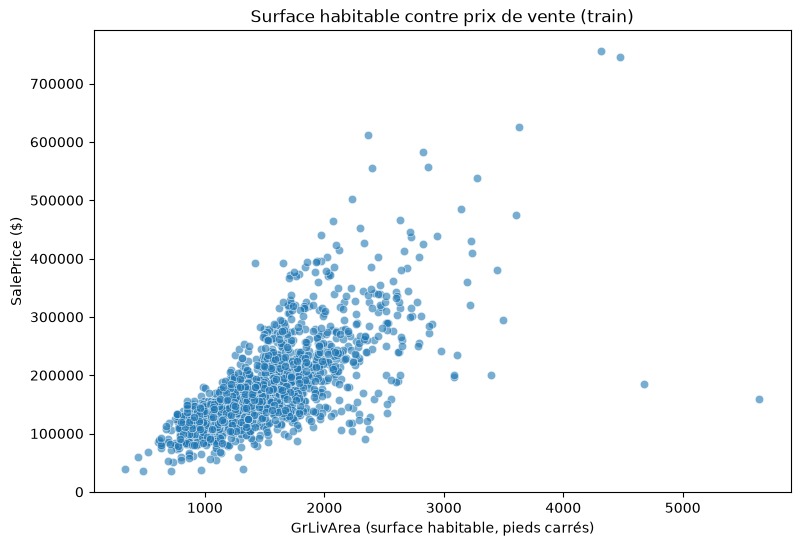

In [1089]:
# Surface habitable contre prix de vente, sur le train
plt.figure(figsize=(9, 6))
sns.scatterplot(data=train, x="GrLivArea", y="SalePrice", alpha=0.6)
plt.title("Surface habitable contre prix de vente (train)")
plt.xlabel("GrLivArea (surface habitable, pieds carrés)")
plt.ylabel("SalePrice ($)")
plt.show()

La tendance est nette : plus la surface augmente, plus le prix monte. Deux points en bas à droite (≈ 4 700 et 5 600 pieds carrés, vendus ≈ 160 000 – 185 000 $) vont à contre-courant. Les deux points en haut à droite (≈ 750 000 $) sont extrêmes mais **suivent la tendance** : maisons de luxe, pas des anomalies.

In [1090]:
# Les deux grandes maisons vendues anormalement peu cher
col_graph1 = ["GrLivArea", "SalePrice", "SaleCondition", "OverallQual","Neighborhood"]
masque_graph1 =  ((train["GrLivArea"] > 4000) & (train["SalePrice"] < 400000))
train.loc[masque_graph1, col_graph1]

,GrLivArea,SalePrice,SaleCondition,OverallQual,Neighborhood
523,4676,184750,Partial,10,Edwards
1298,5642,160000,Partial,10,Edwards


In [1091]:
# Très grandes maisons dans le test
all_X.iloc[n_train:].loc[all_X.iloc[n_train:]["GrLivArea"] > 4000,
                         ["GrLivArea", "SaleCondition", "OverallQual", "Neighborhood"]]

,GrLivArea,SaleCondition,OverallQual,Neighborhood
2549,5095,Partial,10,Edwards


**Conclusion**

| Maison | Surface | Prix | `SaleCondition` | `OverallQual` | Quartier |
|---|---|---|---|---|---|
| 523 (train) | 4 676 | 184 750 $ | Partial | 10 | Edwards |
| 1298 (train) | 5 642 | 160 000 $ | Partial | 10 | Edwards |
| 2549 (test) | 5 095 | — | Partial | 10 | Edwards |

- 523 et 1298 sont d'immenses maisons de qualité maximale, vendues **avant d'être terminées** (`Partial`) dans un quartier modeste, au prix d'une maison moyenne. Leur prix ne reflète pas la relation normale entre la maison et sa valeur ; elles tireraient vers le bas la pente des grandes maisons pour un modèle linéaire.
- Une seule très grande maison dans le test, **2549**, au profil identique (même quartier, même qualité, vente `Partial`, déjà repérée comme vente sur plan) : probablement la même opération immobilière.

**Décision : retirer 523 et 1298 du train** (recommandation de l'auteur du dataset), seulement ces deux-là et non toutes les maisons de plus de 4 000 pieds carrés. Le retrait se fera sur le train **avant** l'extraction de `y`, dans l'étape de prétraitement.

**Limite connue** : entraîné sans ces deux exemples, le modèle prédira probablement un prix élevé pour 2549, dont le vrai prix est sans doute bas. L'erreur ne porte que sur une prédiction (ordre de grandeur : un score de 0,120 passerait à ≈ 0,124 si cette maison était prédite à 3 fois son prix), contre une relation plus juste pour toutes les autres grandes maisons.

## 4. Asymétrie des variables numériques